# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
mammals_df = pd.read_csv("data/mammal_sleep.csv")


In [3]:
mammals_df.head()


,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [4]:
mammals_df.tail()


,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1
61,Yellow-bellied marmot,4.050,17.0,NaN,NaN,NaN,13.0,38.0,3,1,1


In [5]:
mammals_df.shape


(62, 11)

In [6]:
mammals_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     str    
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), str(1)
memory usage: 6.1 KB


In [7]:
mammals_df.isnull().sum()


species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

**What does one row represent?**

Your answer: One row describes one mammal species. It is not one animal or one night's sleep.

**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `species` | Categorical species label | str | 0 |
| `body_weight` | Quantitative | float64 | 0 |
| `brain_weight` | Quantitative | float64 | 0 |
| `non_dreaming_sleep` | Quantitative | float64 | 14 |
| `dreaming_sleep` | Quantitative | float64 | 12 |
| `total_sleep` | Quantitative | float64 | 4 |
| `max_life_span` | Quantitative | float64 | 4 |
| `gestation_time` | Quantitative | float64 | 4 |
| `predation_index` | Categorical, ordered | int64 | 0 |
| `sleep_exposure_index` | Categorical, ordered | int64 | 0 |
| `danger_index` | Categorical, ordered | int64 | 0 |

Your answer: The three ratings are ordered categories, even though they are stored as numbers. Source missing values coded -999 were already converted to blanks in this CSV.


# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer: I expect all three relationships to rise. Total sleep includes both phases, so each phase should be related to the total. I expect non-dreaming sleep to have the stronger link because it may make up more of the total.

## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [8]:
sleep_df = mammals_df.dropna(subset=[
    "dreaming_sleep", "non_dreaming_sleep", "total_sleep", "danger_index", "predation_index"
]).copy()
print("Original species:", len(mammals_df))
print("Retained species:", len(sleep_df))
print("Removed species:", len(mammals_df) - len(sleep_df))
sleep_df[["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]].agg(["min", "max"])


Original species: 62
Retained species: 48
Removed species: 14


,dreaming_sleep,non_dreaming_sleep,total_sleep
min,0.0,2.1,2.9
max,6.6,17.9,19.9


In [9]:
sleep_df[["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]].ge(0).all() & sleep_df[["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]].le(24).all()


dreaming_sleep        True
non_dreaming_sleep    True
total_sleep           True
dtype: bool

## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

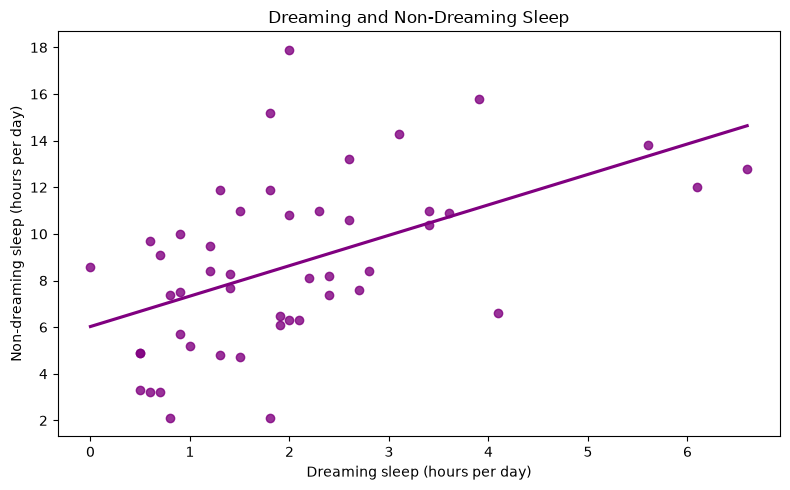

In [10]:
plt.figure(figsize=(8, 5))
sns.regplot(data=sleep_df, x="dreaming_sleep", y="non_dreaming_sleep", color="purple", ci=None)
plt.title("Dreaming and Non-Dreaming Sleep")
plt.xlabel("Dreaming sleep (hours per day)")
plt.ylabel("Non-dreaming sleep (hours per day)")
plt.tight_layout()
plt.show()


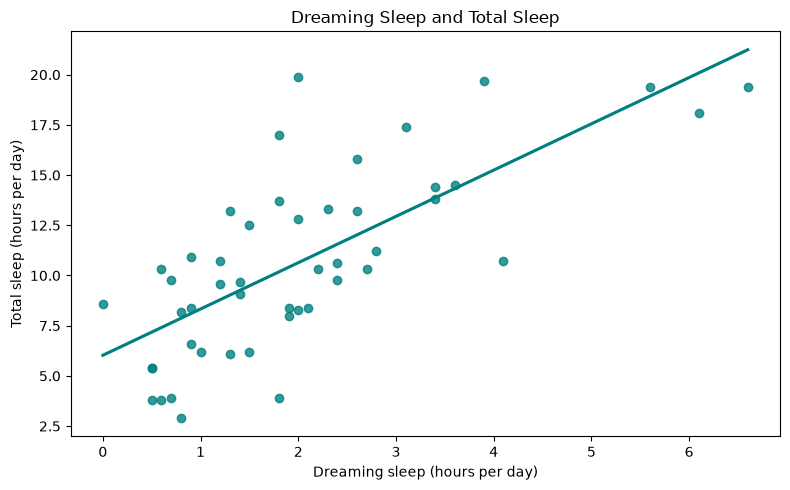

In [11]:
plt.figure(figsize=(8, 5))
sns.regplot(data=sleep_df, x="dreaming_sleep", y="total_sleep", color="teal", ci=None)
plt.title("Dreaming Sleep and Total Sleep")
plt.xlabel("Dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.tight_layout()
plt.show()


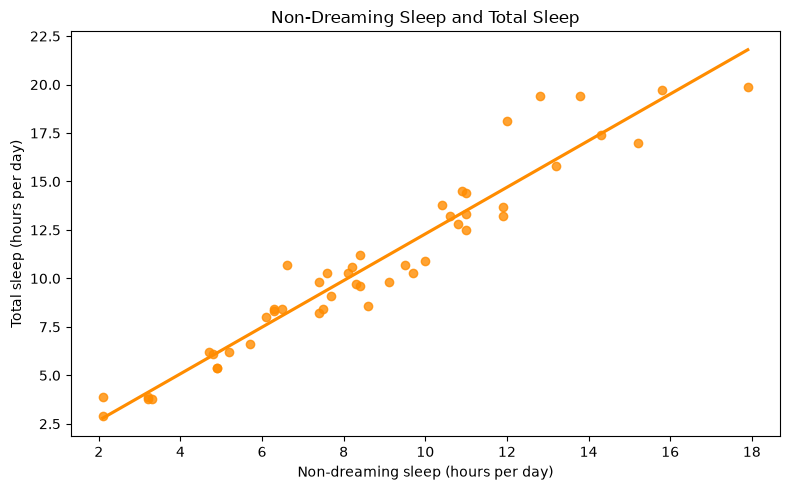

In [12]:
plt.figure(figsize=(8, 5))
sns.regplot(data=sleep_df, x="non_dreaming_sleep", y="total_sleep", color="darkorange", ci=None)
plt.title("Non-Dreaming Sleep and Total Sleep")
plt.xlabel("Non-dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.tight_layout()
plt.show()


In [13]:
sleep_correlations = pd.Series({
    "Dreaming and non-dreaming": sleep_df["dreaming_sleep"].corr(sleep_df["non_dreaming_sleep"]),
    "Dreaming and total": sleep_df["dreaming_sleep"].corr(sleep_df["total_sleep"]),
    "Non-dreaming and total": sleep_df["non_dreaming_sleep"].corr(sleep_df["total_sleep"])
}, name="correlation")
pd.DataFrame({"correlation": sleep_correlations, "r_squared": sleep_correlations ** 2}).round(4)


,correlation,r_squared
Dreaming and non-dreaming,0.5143,0.2645
Dreaming and total,0.7271,0.5287
Non-dreaming and total,0.9627,0.9268


**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer: All three point clouds rise. Dreaming versus non-dreaming has a loose, roughly straight pattern with plenty of scatter, r = 0.5143 and R-squared = 0.2645. Dreaming versus total is more clearly upward but still spread out, r = 0.7271 and R-squared = 0.5287. Non-dreaming versus total is tight and roughly straight, r = 0.9627 and R-squared = 0.9268. The bats have unusually long non-dreaming sleep, and the water opossum has 6.6 hours of dreaming sleep. The last plot fits a straight line best. Its line accounts for about 92.68% of the variation in total sleep across these 48 species, not 92.68% prediction accuracy.


## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [14]:
sleep_df["phase_sum"] = sleep_df["dreaming_sleep"] + sleep_df["non_dreaming_sleep"]
print("All phase sums match total sleep:", np.isclose(sleep_df["phase_sum"], sleep_df["total_sleep"]).all())
sleep_df[["species", "dreaming_sleep", "non_dreaming_sleep", "phase_sum", "total_sleep"]].head()


All phase sums match total sleep: True


,species,dreaming_sleep,non_dreaming_sleep,phase_sum,total_sleep
1,African giant pouched rat,2.0,6.3,8.3,8.3
4,Asian elephant,1.8,2.1,3.9,3.9
5,Baboon,0.7,9.1,9.8,9.8
6,Big brown bat,3.9,15.8,19.7,19.7
7,Brazilian tapir,1.0,5.2,6.2,6.2


In [15]:
sleep_df.nlargest(3, "non_dreaming_sleep")[["species", "dreaming_sleep", "non_dreaming_sleep", "total_sleep"]]


,species,dreaming_sleep,non_dreaming_sleep,total_sleep
32,Little brown bat,2.0,17.9,19.9
6,Big brown bat,3.9,15.8,19.7
41,Owl monkey,1.8,15.2,17.0


## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?

**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer: More dreaming sleep generally goes with more non-dreaming sleep, but the link is only moderate at r = 0.5143. Non-dreaming sleep is much more strongly related to total sleep, with r = 0.9627 and R-squared = 0.9268, compared with 0.7271 and 0.5287 for dreaming sleep. The tighter non-dreaming plot supports the prediction. The 48 complete species are used in every comparison, with 14 species removed for missing required measurements.


## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer: First, total sleep is the sum of the two phases, so part of the strong relationship is built into the measurements. It does not show that one phase causes the total. Second, these 48 complete historical species records are not a random sample of all mammals, and related species may not be independent. A stronger correlation alone does not explain the biology or make a better scientific model.


# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?**

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer: I expect both ratings to add only a little beyond non-dreaming sleep. I would look for different total sleep values between rating groups at similar non-dreaming sleep durations, not just groups with different horizontal ranges.

## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [16]:
sleep_df["danger_index"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)


danger_index
1    14
2    12
3     8
4     9
5     5
Name: count, dtype: int64

In [17]:
sleep_df["predation_index"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)


predation_index
1    10
2    13
3     9
4     7
5     9
Name: count, dtype: int64

In [18]:
pd.crosstab(sleep_df["danger_index"], sleep_df["predation_index"]).reindex(index=[1, 2, 3, 4, 5], columns=[1, 2, 3, 4, 5], fill_value=0)


predation_index,1,2,3,4,5
danger_index,,,,,
1,10,4,0,0,0
2,0,9,3,0,0
3,0,0,5,2,1
4,0,0,1,5,3
5,0,0,0,0,5


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

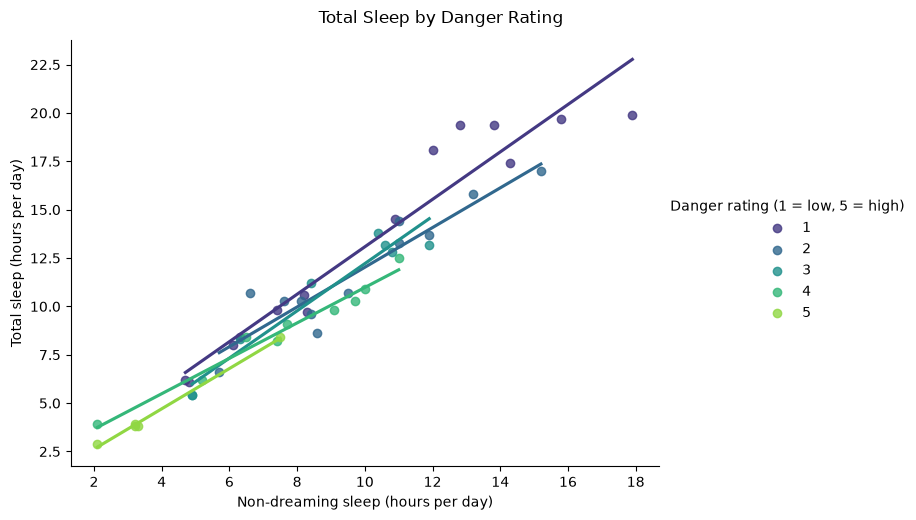

In [19]:
group_plot = sns.lmplot(
    data=sleep_df, x="non_dreaming_sleep", y="total_sleep", hue="danger_index",
    hue_order=[1, 2, 3, 4, 5], palette="viridis", ci=None, legend=False, height=5, aspect=1.4
)
group_plot.add_legend(title="Danger rating (1 = low, 5 = high)")
group_plot.set_axis_labels("Non-dreaming sleep (hours per day)", "Total sleep (hours per day)")
group_plot.figure.suptitle("Total Sleep by Danger Rating", y=1.03)
plt.show()


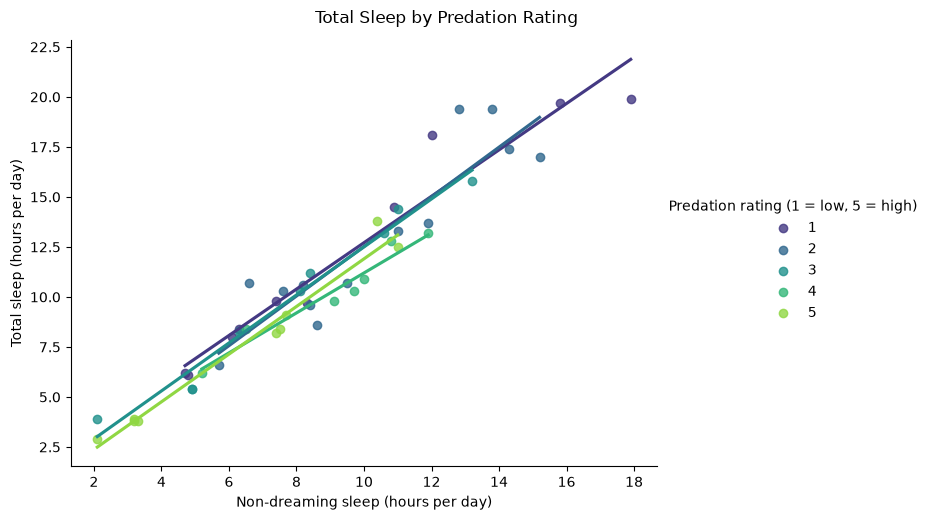

In [20]:
group_plot = sns.lmplot(
    data=sleep_df, x="non_dreaming_sleep", y="total_sleep", hue="predation_index",
    hue_order=[1, 2, 3, 4, 5], palette="viridis", ci=None, legend=False, height=5, aspect=1.4
)
group_plot.add_legend(title="Predation rating (1 = low, 5 = high)")
group_plot.set_axis_labels("Non-dreaming sleep (hours per day)", "Total sleep (hours per day)")
group_plot.figure.suptitle("Total Sleep by Predation Rating", y=1.03)
plt.show()


**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer: Both plots show lots of overlap along the main upward trend. Danger groups show some separation at similar non-dreaming durations, while predation lines are mostly close. The danger groups have 14, 12, 8, 9, and 5 species, and predation groups have 10, 13, 9, 7, and 9. Danger level 5 covers only 2.1 to 7.5 hours of non-dreaming sleep. Its short range and small size make its line less stable, so I would not compare it with long-sleeping species outside that range.


### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [21]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [22]:
phase_comparison = pd.Series({
    "Baseline": calculate_r_squared(sleep_df, "non_dreaming_sleep", "total_sleep", []),
    "Baseline + danger": calculate_r_squared(sleep_df, "non_dreaming_sleep", "total_sleep", ["danger_index"]),
    "Baseline + predation": calculate_r_squared(sleep_df, "non_dreaming_sleep", "total_sleep", ["predation_index"]),
    "Baseline + both": calculate_r_squared(sleep_df, "non_dreaming_sleep", "total_sleep", ["danger_index", "predation_index"])
}, name="r_squared")
pd.DataFrame({"r_squared": phase_comparison, "change_from_baseline": phase_comparison - phase_comparison.loc["Baseline"]}).round(4)


,r_squared,change_from_baseline
Baseline,0.9268,0.0000
Baseline + danger,0.9427,0.0158
Baseline + predation,0.9371,0.0103
Baseline + both,0.9515,0.0246


## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

In [23]:
sleep_df.groupby("danger_index")["non_dreaming_sleep"].agg(["count", "min", "max"])


,count,min,max
danger_index,,,
1,14,4.7,17.9
2,12,5.7,15.2
3,8,4.9,11.9
4,9,2.1,11.0
5,5,2.1,7.5


In [24]:
sleep_df.groupby("predation_index")["non_dreaming_sleep"].agg(["count", "min", "max"])


,count,min,max
predation_index,,,
1,10,4.7,17.9
2,13,5.7,15.2
3,9,2.1,13.2
4,7,5.2,11.9
5,9,2.1,11.0


**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer: Danger group 1 ranges from 4.7 to 17.9 hours and group 5 from 2.1 to 7.5 hours. Their horizontal ranges overlap from 4.7 to 7.5 hours. That is the useful span for comparing their lines. Outside it, at least one line would be extending beyond that group's data. Even within the span, observations are sparse rather than present at every duration.


## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer: All three additions improve the fit a little. R-squared is 0.9268 for non-dreaming sleep alone, 0.9427 with danger, 0.9371 with predation, and 0.9515 with both. The increases from baseline are 0.0158, 0.0103, and 0.0246. These are small gains, matching the prediction and the heavy overlap in the plots. The model already fits closely without the ratings. The plotted group lines have separate slopes, while the additive models use one shared slope.


## Step 6: Limitation

**Identify two limitations of this investigation.**

Your answer: Some rating groups are small and cover different sleep ranges, so their lines can change a lot with a few species. Also, danger includes related risk information, so the two ratings are not independent explanations. Adding predictors raises training fit without proving causation or better predictions for new species.


# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer: I expect longer pregnancies to go with fewer hours of sleep. Large mammals may have longer pregnancies and spend more time feeding or moving, but the data needs to show whether that guess fits.

## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [25]:
gestation_df = mammals_df.dropna(subset=[
    "gestation_time", "total_sleep", "danger_index", "predation_index"
]).copy()
print("Retained species:", len(gestation_df))
print("Removed species:", len(mammals_df) - len(gestation_df))
gestation_df[["gestation_time", "total_sleep"]].agg(["min", "max"])


Retained species: 54
Removed species: 8


,gestation_time,total_sleep
min,12.0,2.6
max,645.0,19.9


In [26]:
print("All gestation times positive:", gestation_df["gestation_time"].gt(0).all())
print("All sleep values between 0 and 24:", gestation_df["total_sleep"].between(0, 24).all())


All gestation times positive: True
All sleep values between 0 and 24: True


In [27]:
gestation_df["log10_gestation_time"] = np.log10(gestation_df["gestation_time"])


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

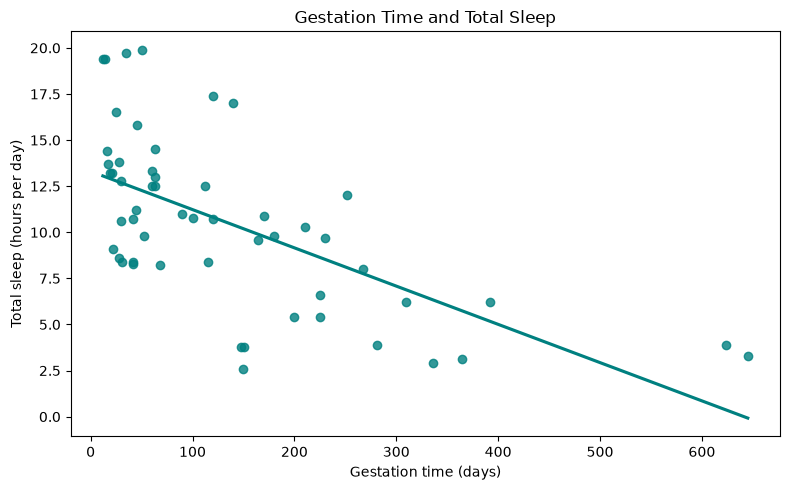

In [28]:
plt.figure(figsize=(8, 5))
sns.regplot(data=gestation_df, x="gestation_time", y="total_sleep", color="teal", ci=None)
plt.title("Gestation Time and Total Sleep")
plt.xlabel("Gestation time (days)")
plt.ylabel("Total sleep (hours per day)")
plt.tight_layout()
plt.show()


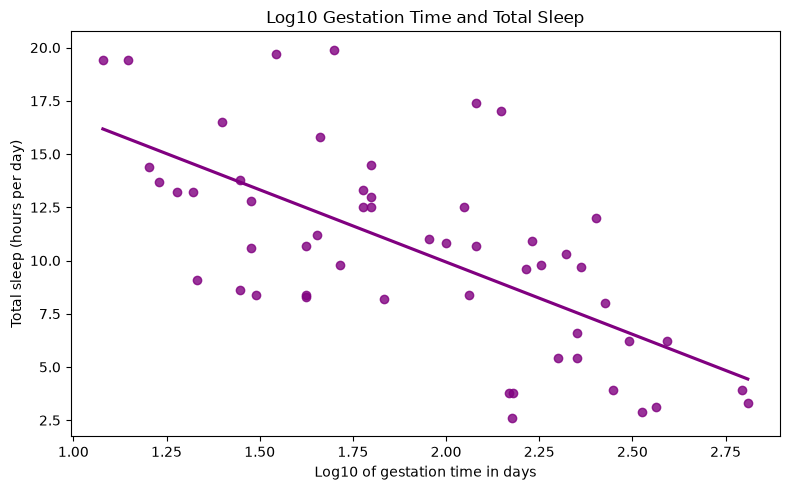

In [29]:
plt.figure(figsize=(8, 5))
sns.regplot(data=gestation_df, x="log10_gestation_time", y="total_sleep", color="purple", ci=None)
plt.title("Log10 Gestation Time and Total Sleep")
plt.xlabel("Log10 of gestation time in days")
plt.ylabel("Total sleep (hours per day)")
plt.tight_layout()
plt.show()


In [30]:
gestation_correlations = pd.Series({
    "Original gestation": gestation_df["gestation_time"].corr(gestation_df["total_sleep"]),
    "Log10 gestation": gestation_df["log10_gestation_time"].corr(gestation_df["total_sleep"])
}, name="correlation")
pd.DataFrame({"correlation": gestation_correlations, "r_squared": gestation_correlations ** 2}).round(4)


,correlation,r_squared
Original gestation,-0.6313,0.3986
Log10 gestation,-0.6637,0.4404


**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer: The original plot bends downward and levels off as gestation gets longer. Taking log10 spreads out the shorter pregnancies and compresses the longer ones, making the pattern somewhat straighter. Correlation changes from -0.6313 to -0.6637, and R-squared rises from 0.3986 to 0.4404. That is a modest improvement. The points still scatter widely, and total sleep stays in hours per day.


Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [31]:
gestation_df["danger_index"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)


danger_index
1    16
2    12
3    10
4     9
5     7
Name: count, dtype: int64

In [32]:
gestation_df["predation_index"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)


predation_index
1    12
2    14
3     9
4     7
5    12
Name: count, dtype: int64

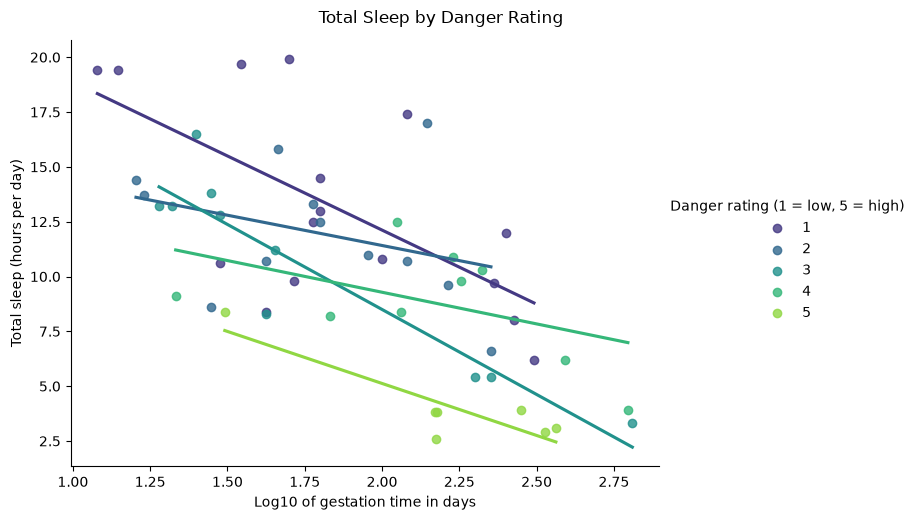

In [33]:
group_plot = sns.lmplot(
    data=gestation_df, x="log10_gestation_time", y="total_sleep", hue="danger_index",
    hue_order=[1, 2, 3, 4, 5], palette="viridis", ci=None, legend=False, height=5, aspect=1.4
)
group_plot.add_legend(title="Danger rating (1 = low, 5 = high)")
group_plot.set_axis_labels("Log10 of gestation time in days", "Total sleep (hours per day)")
group_plot.figure.suptitle("Total Sleep by Danger Rating", y=1.03)
plt.show()


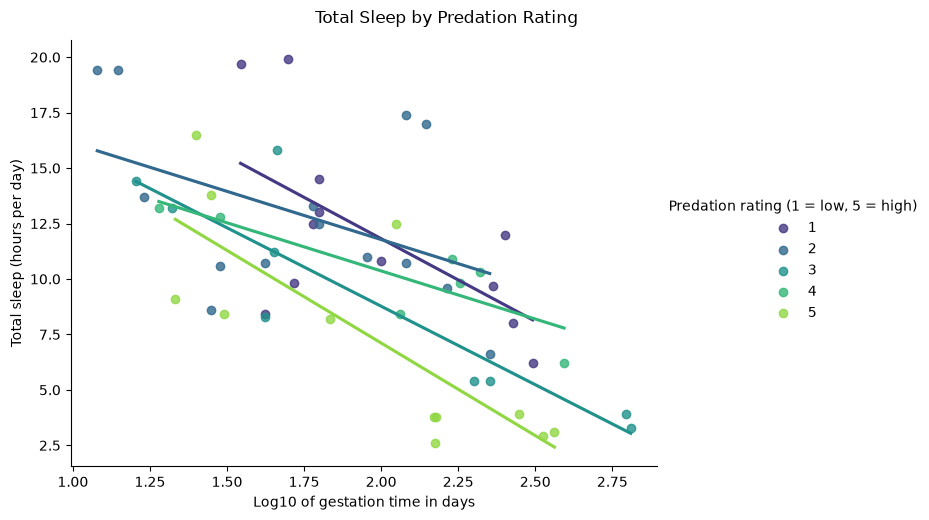

In [34]:
group_plot = sns.lmplot(
    data=gestation_df, x="log10_gestation_time", y="total_sleep", hue="predation_index",
    hue_order=[1, 2, 3, 4, 5], palette="viridis", ci=None, legend=False, height=5, aspect=1.4
)
group_plot.add_legend(title="Predation rating (1 = low, 5 = high)")
group_plot.set_axis_labels("Log10 of gestation time in days", "Total sleep (hours per day)")
group_plot.figure.suptitle("Total Sleep by Predation Rating", y=1.03)
plt.show()


In [35]:
sleep_comparison = pd.Series({
    "Baseline": calculate_r_squared(gestation_df, "log10_gestation_time", "total_sleep", []),
    "Baseline + danger": calculate_r_squared(gestation_df, "log10_gestation_time", "total_sleep", ["danger_index"]),
    "Baseline + predation": calculate_r_squared(gestation_df, "log10_gestation_time", "total_sleep", ["predation_index"]),
    "Baseline + both": calculate_r_squared(gestation_df, "log10_gestation_time", "total_sleep", ["danger_index", "predation_index"])
}, name="r_squared")
pd.DataFrame({"r_squared": sleep_comparison, "change_from_baseline": sleep_comparison - sleep_comparison.loc["Baseline"]}).round(4)


,r_squared,change_from_baseline
Baseline,0.4404,0.0000
Baseline + danger,0.6542,0.2137
Baseline + predation,0.5917,0.1512
Baseline + both,0.6943,0.2538


## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [36]:
gestation_df["recovered_days"] = 10 ** gestation_df["log10_gestation_time"]
print("Reversed logs match original days:", np.isclose(gestation_df["recovered_days"], gestation_df["gestation_time"]).all())
gestation_df[["species", "gestation_time", "log10_gestation_time", "recovered_days"]].head()


Reversed logs match original days: True


,species,gestation_time,log10_gestation_time,recovered_days
0,African elephant,645.0,2.809560,645.0
1,African giant pouched rat,42.0,1.623249,42.0
2,Arctic Fox,60.0,1.778151,60.0
3,Arctic ground squirrel,25.0,1.397940,25.0
4,Asian elephant,624.0,2.795185,624.0


In [37]:
gestation_df.loc[
    [gestation_df["gestation_time"].idxmin(), gestation_df["gestation_time"].idxmax()],
    ["species", "gestation_time", "log10_gestation_time", "total_sleep"]
]


,species,gestation_time,log10_gestation_time,total_sleep
38,N. American opossum,12.0,1.079181,19.4
0,African elephant,645.0,2.809560,3.3


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer: Yes, reversing the logarithm recovered the original days within normal rounding. The North American opossum has 12 days of gestation and 19.4 hours of sleep. The African elephant has 645 days and 3.3 hours. Their horizontal positions change from 12 and 645 to about 1.079 and 2.810, but their sleep heights stay 19.4 and 3.3 in both plots.


## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer: Longer pregnancies generally go with less sleep in these 54 species. The log version is a bit straighter, with r = -0.6637 and R-squared = 0.4404, compared with -0.6313 and 0.3986 on the original gestation scale. With log gestation, adding danger raises R-squared to 0.6542, predation to 0.5917, and both to 0.6943. Those are gains of 0.2137, 0.1512, and 0.2538. The colored plots also show more separation than in the non-dreaming analysis, though groups still overlap. The direction matches the prediction. All four models use the same 54 species, with 8 removed for missing required values.


## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer: The ratings are broad, related categories, and some groups have only 7 species. Their differences do not prove that danger or gestation causes sleep patterns. The models also use historical species summaries with missing records, not new animals tested separately. Higher training R-squared does not establish how well the model works on other species.


## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: Did not use AI for this lab

## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.